# Procurement Spend V2 — análise exploratória
**P5.4 · dados sintéticos · 04/11/2026**

Unidade de análise: linha de compra. Esta EDA descreve preços, quantidades, fornecedores e resultados de entrega; não treina modelos, não executa inferência e não define fraude ou risco empresarial.

A V1 Invoice (19 features), Supplier Risk e a fonte Purchase anterior permanecem independentes. Nenhum módulo dessas linhas é importado.

**Execução:** executar as células em ordem, a partir da raiz do repositório ou de `ml/procurement_v2/notebooks/`, em ambiente com Python, pandas, NumPy e matplotlib. Para execução interativa é necessário um kernel Jupyter já disponível. Não há instalação automática. Tabelas e gráficos ficam somente na memória/saída deste notebook.

**Fonte:** [repositório](https://github.com/dytcoke23/procurement-spend-analysis-dashboard), commit `3799e2e921ce0d5631bd4555c40915747d543ada`. [Gerador consultado por leitura](https://github.com/dytcoke23/procurement-spend-analysis-dashboard/blob/3799e2e921ce0d5631bd4555c40915747d543ada/scripts/generate_data.py), [licença MIT](https://github.com/dytcoke23/procurement-spend-analysis-dashboard/blob/3799e2e921ce0d5631bd4555c40915747d543ada/LICENSE), copyright 2026 Harsh. O gerador não é importado nem executado.

**Moeda:** a fonte não possui código ISO; “UM sintética” significa unidade monetária não especificada. Não interpretar como BRL ou USD. Unidades físicas pertencem ao item e não são somadas entre itens diferentes.

In [1]:
import csv
import hashlib
import io
import platform
from decimal import Decimal
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

EXPECTED_SHA256 = "fba22a467e5dd800a0af960930d2ca5e2ecbd9d2bc747e37304867d8d031ae21"
cwd = Path.cwd()
if (cwd / "ml/procurement_v2/notebooks").is_dir():
    ROOT = cwd
elif cwd.name == "notebooks" and cwd.parent.name == "procurement_v2" and cwd.parent.parent.name == "ml":
    ROOT = cwd.parents[2]
else:
    raise RuntimeError("Execute da raiz do projeto ou do diretório deste notebook.")
DATA_PATH = ROOT / "data/external/procurement_spend/purchase_orders.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("CSV ausente no caminho autorizado; sem busca alternativa.")

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.prop_cycle": plt.cycler(color=["#176B87", "#E48B35", "#4B826E", "#845BA5", "#A14C57", "#766B45"]),
})

def table(frame, rows=None):
    """Exibição; a tabela completa continua disponível na variável correspondente."""
    view = frame if rows is None else frame.head(rows)
    rich_display = globals().get("display")
    if callable(rich_display):
        rich_display(view)
    else:
        print(view.to_string())

def show(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

environment = {"Python": platform.python_version(),
               **{name: version(name) for name in ("pandas", "numpy", "matplotlib")}}
print(environment)

{'Python': '3.14.3', 'pandas': '2.3.3', 'numpy': '2.5.2', 'matplotlib': '3.11.2'}


In [2]:
raw_bytes = DATA_PATH.read_bytes()
assert hashlib.sha256(raw_bytes).hexdigest() == EXPECTED_SHA256, "Hash divergente: não prosseguir."
expected_columns = [
    "po_id", "order_date", "promised_delivery_date", "actual_delivery_date",
    "supplier_id", "supplier_name", "supplier_country", "category", "item",
    "business_unit", "unit_price", "quantity", "line_total", "payment_terms",
    "on_contract", "quality_rejected",
]
raw = pd.read_csv(io.BytesIO(raw_bytes))
assert list(raw.columns) == expected_columns
assert raw.shape == (47128, 16)
assert not raw.isna().any().any()
assert not raw.duplicated().any() and raw["po_id"].is_unique
for col in raw.select_dtypes("object"):
    assert raw[col].str.strip().eq(raw[col]).all() and raw[col].str.len().gt(0).all()
for col in ("unit_price", "quantity", "line_total"):
    assert np.isfinite(raw[col]).all() and raw[col].gt(0).all()
assert raw["quantity"].mod(1).eq(0).all()
for col in ("on_contract", "quality_rejected"):
    assert raw[col].dtype == bool
decimal_mismatches = sum(
    Decimal(row["unit_price"]) * Decimal(row["quantity"]) != Decimal(row["line_total"])
    for row in csv.DictReader(io.StringIO(raw_bytes.decode("utf-8-sig")))
)
assert decimal_mismatches == 0
raw_fingerprint = pd.util.hash_pandas_object(raw, index=True).to_numpy().copy()
df = raw.copy(deep=True)
for col in ("order_date", "promised_delivery_date", "actual_delivery_date"):
    assert df[col].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all()
    df[col] = pd.to_datetime(df[col], format="%Y-%m-%d", errors="raise")
df["month"] = df["order_date"].dt.to_period("M")
df["year"] = df["order_date"].dt.year
df["quarter"] = df["order_date"].dt.to_period("Q")
df["planned_days"] = (df["promised_delivery_date"] - df["order_date"]).dt.days
df["delay_days"] = (df["actual_delivery_date"] - df["promised_delivery_date"]).dt.days
df["late"] = df["delay_days"].gt(0)
df["off_contract"] = ~df["on_contract"]
assert df["payment_terms"].isin(["Net 15", "Net 30", "Net 45", "Net 60"]).all()
df["payment_days"] = df["payment_terms"].str.extract(r"^Net (\d+)$")[0].astype(int)
assert df["planned_days"].ge(0).all()
assert df["actual_delivery_date"].ge(df["order_date"]).all()
assert df.groupby("supplier_id")["supplier_name"].nunique().eq(1).all()
assert df.groupby("supplier_id")["supplier_country"].nunique().eq(1).all()
assert df.groupby("supplier_id")["category"].nunique().eq(1).all()
assert df.groupby("item")["category"].nunique().eq(1).all()
profile = pd.DataFrame({"tipo_CSV": raw.dtypes.astype(str), "ausentes": raw.isna().sum(),
                        "distintos": raw.nunique()})
table(profile)
print(f"{len(df):,} linhas; {df.supplier_id.nunique()} fornecedores; "
      f"{df.item.nunique()} itens; {df.category.nunique()} categorias; "
      f"{df.business_unit.nunique()} unidades de negócio; {df.month.nunique()} meses.")
print("Datas dos pedidos:", df.order_date.min().date(), "a", df.order_date.max().date())
print("Última entrega efetiva:", df.actual_delivery_date.max().date())
print("Divergências monetárias decimais:", decimal_mismatches)

,tipo_CSV,ausentes,distintos
po_id,object,0,47128
order_date,object,0,1277
promised_delivery_date,object,0,1304
actual_delivery_date,object,0,1310
supplier_id,object,0,106
supplier_name,object,0,106
supplier_country,object,0,10
category,object,0,10
item,object,0,50
business_unit,object,0,5


47,128 linhas; 106 fornecedores; 50 itens; 10 categorias; 5 unidades de negócio; 42 meses.
Datas dos pedidos: 2023-01-01 a 2026-06-30
Última entrega efetiva: 2026-08-12
Divergências monetárias decimais: 0


## O que já foi programado na fonte

| Mecanismo do gerador | Consequência para a interpretação |
|---|---|
| Seed 42; catálogo de 50 itens, cinco por categoria | Reprodutibilidade artificial; não são registros de uma empresa |
| Preço-base × fator do fornecedor × inflação da categoria × ruído | Crescimento e diferenças de preço não são descobertas independentes |
| Inflação anual de 2% a 13% | Comparar preços em momentos próximos; tendência não equivale a anomalia |
| Seis fornecedores com maior ruído de preço, atrasos e rejeições | Perfis deliberados; a classe latente não está no CSV |
| Quantidade normal em torno da quantidade típica, truncada para inteiro ≥1 | Extremos podem ser caudas esperadas; não há label de quantidade fraudulenta |
| Maior demanda em março e no quarto trimestre | Sazonalidade introduzida explicitamente |
| Compra fora de contrato: 32% Field Services, 24% R&D, 5% demais | O indicador acompanha uma regra da simulação, sem contrato verificável |
| Machinery: dois fornecedores com pesos 40 e 0,8 | Concentração forte, não fornecedor literalmente único |
| 40 cópias com pedido deslocado 1–2 dias e ID novo | Quase duplicatas plantadas; as datas de entrega são preservadas |
| Atraso truncado em zero; todas as entregas preenchidas | Sem entregas antecipadas, pedidos abertos ou censura observada |

O notebook separa essas regras das estatísticas calculadas abaixo. Nenhum ranking descritivo reconstrói ou certifica o `is_risky` latente.

,lines,spend,months,suppliers,monthly_mean_lines,monthly_mean_spend
year,,,,,,
2023,13798,1.094580e+08,12,106,1149.833333,9.121500e+06
2024,13457,1.153681e+08,12,105,1121.416667,9.614005e+06
2025,13583,1.250258e+08,12,105,1131.916667,1.041882e+07
2026,6290,6.133143e+07,6,101,1048.333333,1.022191e+07


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
unit_price,47128.0,1882.571516,3162.264458,3.26,4.8000,58.385,437.460,1992.005,9995.1615,12821.8559,16291.25
line_total,47128.0,8724.820388,8340.915877,4.52,325.1229,2982.390,5802.135,11505.850,26825.0865,36744.9042,68025.18


Frequência diária (linhas/dia): {'count': 1277.0, 'mean': 36.91, 'std': 8.11, 'min': 13.0, '25%': 31.0, '50%': 36.0, '75%': 42.0, 'max': 68.0}


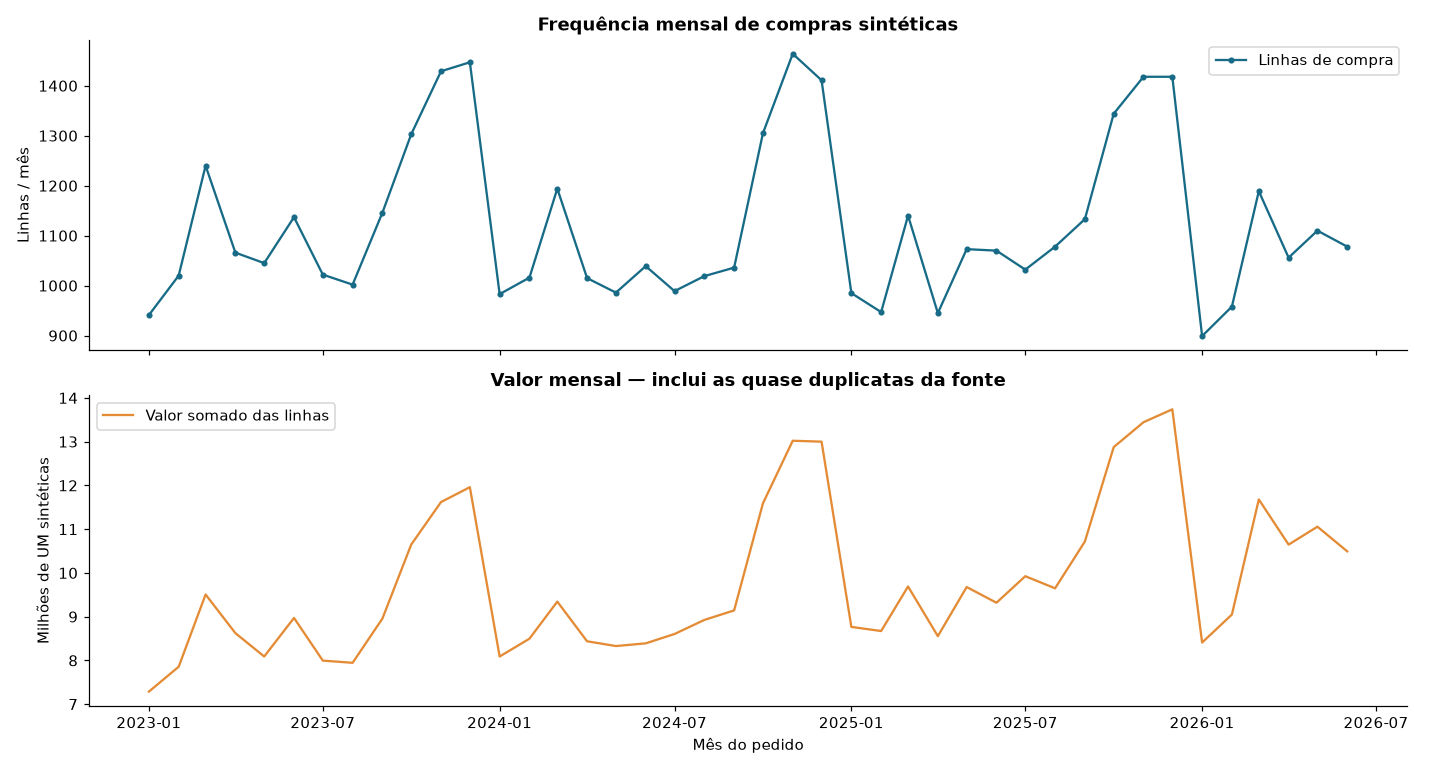

In [3]:
monthly = df.groupby("month").agg(
    lines=("po_id", "size"), spend=("line_total", "sum"),
    suppliers=("supplier_id", "nunique"), median_line=("line_total", "median"),
)
annual = df.groupby("year").agg(
    lines=("po_id", "size"), spend=("line_total", "sum"),
    months=("month", "nunique"), suppliers=("supplier_id", "nunique"),
)
annual["monthly_mean_lines"] = annual["lines"] / annual["months"]
annual["monthly_mean_spend"] = annual["spend"] / annual["months"]
daily = df.groupby("order_date").size().reindex(
    pd.date_range(df.order_date.min(), df.order_date.max(), freq="D"), fill_value=0)
money_distribution = df[["unit_price", "line_total"]].describe(
    percentiles=[.01, .25, .5, .75, .95, .99]).T
table(annual)
table(money_distribution)
print("Frequência diária (linhas/dia):", daily.describe().round(2).to_dict())
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
dates = monthly.index.to_timestamp()
axes[0].plot(dates, monthly["lines"], marker=".", label="Linhas de compra")
axes[0].set(title="Frequência mensal de compras sintéticas", ylabel="Linhas / mês")
axes[0].legend()
axes[1].plot(dates, monthly["spend"] / 1e6, color="#E48B35", label="Valor somado das linhas")
axes[1].set(title="Valor mensal — inclui as quase duplicatas da fonte", ylabel="Milhões de UM sintéticas",
            xlabel="Mês do pedido")
axes[1].legend()
show(fig)

## Distribuições e sazonalidade
Os histogramas monetários agregados descrevem a mistura do catálogo; seus extremos não identificam anomalias por si só. A quantidade agregada é normalizada pela mediana do **mesmo item** somente para visualização retrospectiva. Quantidades físicas de itens diferentes não são somadas.

2026 contém apenas seis meses: sua soma anual não deve ser comparada diretamente às somas de anos completos. O perfil sazonal abaixo usa somente 2023–2025 e normaliza cada mês pela média mensal do seu próprio ano.

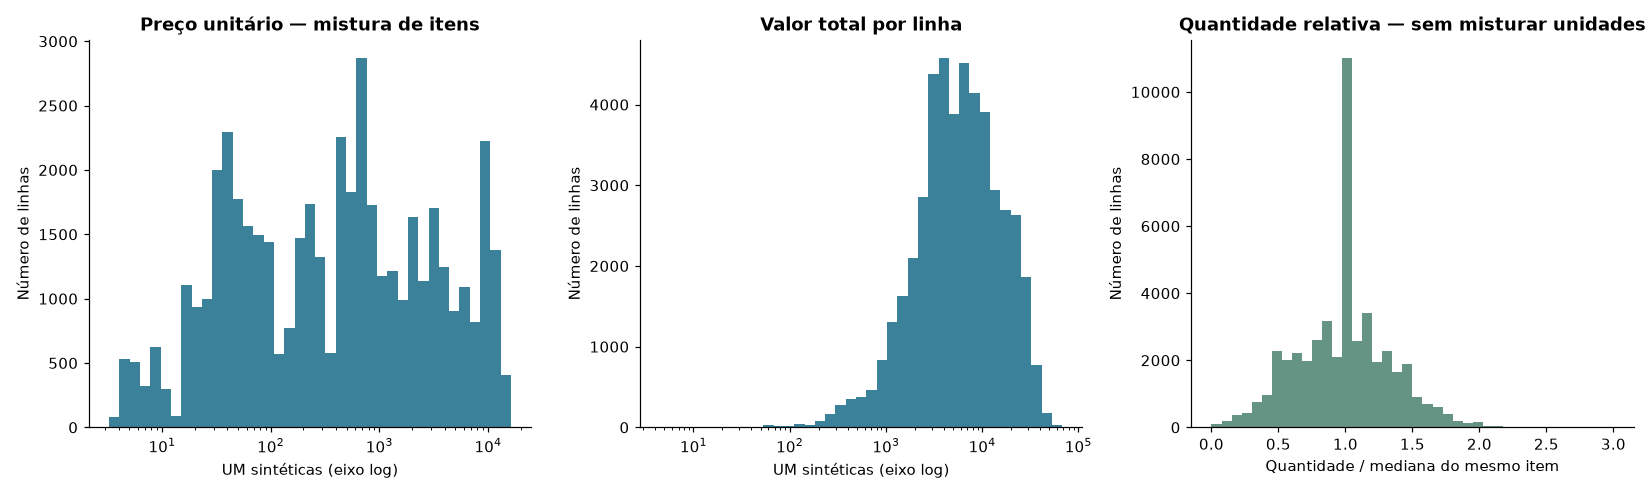

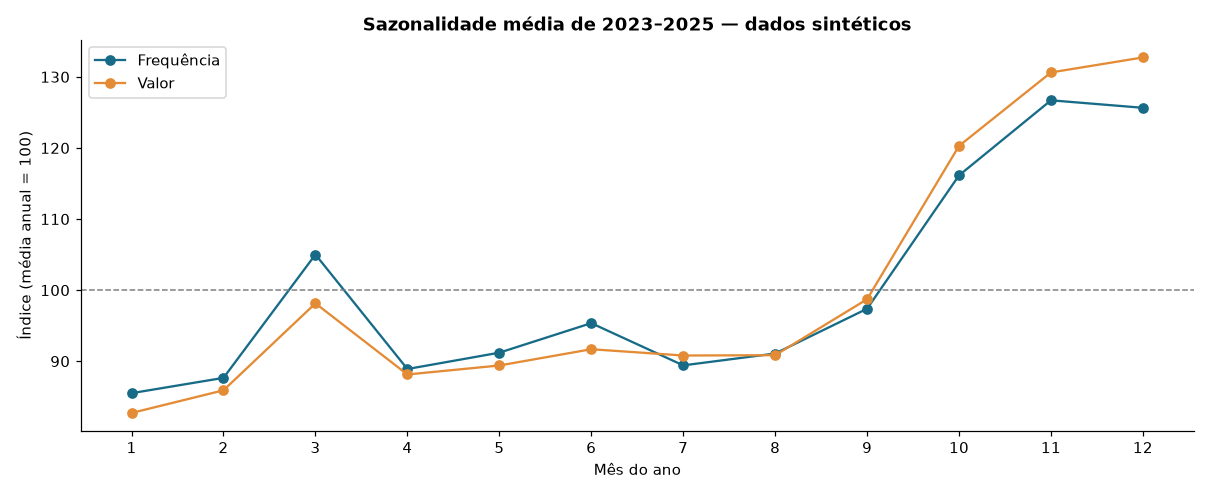

,lines_index,spend_index
month_number,,
1,85.51,82.72
2,87.66,85.91
3,105.01,98.14
4,88.90,88.14
5,91.20,89.40
6,95.35,91.69
7,89.42,90.80
8,91.08,90.85
9,97.38,98.72


In [4]:
df["quantity_relative_item"] = df["quantity"] / df.groupby("item")["quantity"].transform("median")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, title in zip(axes[:2], ("unit_price", "line_total"),
                          ("Preço unitário — mistura de itens", "Valor total por linha"), strict=True):
    bins = np.geomspace(df[col].min(), df[col].max(), 40)
    ax.hist(df[col], bins=bins, color="#176B87", alpha=.85)
    ax.set(xscale="log", xlabel="UM sintéticas (eixo log)", ylabel="Número de linhas", title=title)
axes[2].hist(df["quantity_relative_item"], bins=40, color="#4B826E", alpha=.85)
axes[2].set(xlabel="Quantidade / mediana do mesmo item", ylabel="Número de linhas",
            title="Quantidade relativa — sem misturar unidades")
show(fig)
complete = monthly[monthly.index.year < 2026].copy()
complete["month_number"] = complete.index.month
complete["year_number"] = complete.index.year
complete["lines_index"] = 100 * complete["lines"] / complete.groupby("year_number")["lines"].transform("mean")
complete["spend_index"] = 100 * complete["spend"] / complete.groupby("year_number")["spend"].transform("mean")
seasonal = complete.groupby("month_number")[["lines_index", "spend_index"]].mean()
fig, ax = plt.subplots(figsize=(11, 4.5))
for col, label in (("lines_index", "Frequência"), ("spend_index", "Valor")):
    ax.plot(seasonal.index, seasonal[col], marker="o", label=label)
ax.axhline(100, color="gray", linestyle="--", linewidth=1)
ax.set(xticks=range(1, 13), xlabel="Mês do ano", ylabel="Índice (média anual = 100)",
       title="Sazonalidade média de 2023–2025 — dados sintéticos")
ax.legend()
show(fig)
table(seasonal.round(2))

In [5]:
item_month = df.groupby(["item", "month"])["unit_price"].median().rename("monthly_median")
df = df.join(item_month, on=["item", "month"])
df["relative_month_price"] = df["unit_price"] / df["monthly_median"]
items = df.groupby("item").agg(
    category=("category", "first"), lines=("po_id", "size"), suppliers=("supplier_id", "nunique"),
    price_mean=("unit_price", "mean"), price_median=("unit_price", "median"),
    price_min=("unit_price", "min"), price_max=("unit_price", "max"), price_std=("unit_price", "std"),
    quantity_median=("quantity", "median"), quantity_min=("quantity", "min"), quantity_max=("quantity", "max"),
    relative_price_mean=("relative_month_price", "mean"), relative_price_std=("relative_month_price", "std"),
)
items["raw_price_cv"] = items["price_std"] / items["price_mean"]
items["within_month_price_cv"] = items["relative_price_std"] / items["relative_price_mean"]
item_price_wide = item_month.unstack("month")
items["median_price_change_pct"] = 100 * (
    item_price_wide[pd.Period("2026-06")] / item_price_wide[pd.Period("2023-01")] - 1)
table(items.sort_index().round(4))  # Todos os 50 itens; respeitar a unidade específica de cada item.
volatile_items = items.sort_values("within_month_price_cv", ascending=False)
table(volatile_items[["lines", "suppliers", "raw_price_cv", "within_month_price_cv",
                      "median_price_change_pct"]].head(10).round(4))

,category,lines,suppliers,price_mean,price_median,price_min,price_max,price_std,quantity_median,quantity_min,quantity_max,relative_price_mean,relative_price_std,raw_price_cv,within_month_price_cv,median_price_change_pct
item,,,,,,,,,,,,,,,,
Adhesive Compound (drum),Chemicals,1001,13,666.0357,657.170,457.05,922.22,84.0091,9.0,1,21,0.9882,0.0696,0.1261,0.0705,46.7592
Air Freight (per 100kg),Logistics,1105,10,655.1065,650.590,520.50,850.18,53.3380,5.0,1,11,1.0069,0.0624,0.0814,0.0620,18.6948
Aluminium Sheet (per ton),Raw Materials,1258,10,2650.2763,2641.565,1689.61,3838.38,302.7625,7.0,1,21,1.0132,0.0845,0.1142,0.0834,29.5234
Audit & Compliance Review,Professional Services,646,10,10561.7977,10557.755,8304.29,13127.19,936.0021,1.0,1,2,0.9981,0.0749,0.0886,0.0751,15.4581
Bubble Wrap Rolls,Packaging,1172,10,29.7542,29.750,23.61,38.44,1.8749,86.0,1,191,1.0012,0.0485,0.0630,0.0485,16.8440
CNC Spare Parts Kit,Machinery,278,2,3800.9620,3801.680,3050.97,4380.94,211.9896,2.0,1,3,0.9997,0.0445,0.0558,0.0446,10.1260
Catalyst Powder (per 25kg),Chemicals,987,14,1129.7366,1118.780,783.30,1498.21,140.1373,5.0,1,10,0.9915,0.0672,0.1240,0.0678,45.1162
Cleaning Agent (drum),Chemicals,943,14,244.2969,241.540,171.30,329.62,30.1027,21.0,1,47,0.9921,0.0659,0.1232,0.0664,45.0950
Cloud Hosting (monthly block),IT Services,658,8,4570.4357,4571.125,3711.57,5451.05,252.3812,1.0,1,2,1.0005,0.0463,0.0552,0.0462,10.1744


,lines,suppliers,raw_price_cv,within_month_price_cv,median_price_change_pct
item,,,,,
Machine Lubricant (drum),1191,10,0.1070,0.1027,7.9254
Safety Gloves (per 100),1241,10,0.1056,0.1012,10.5310
Industrial Bearings,1231,10,0.1045,0.0987,10.8040
Conveyor Belt Section,1225,10,0.1023,0.0987,10.9699
Hydraulic Fluid (drum),1284,10,0.1034,0.0980,8.1217
Steel Coil (per ton),1296,10,0.1153,0.0841,34.6699
PCB Assembly A-11,1204,15,0.1451,0.0836,42.8206
Aluminium Sheet (per ton),1258,10,0.1142,0.0834,29.5234
Power Supply Unit 450W,1319,15,0.1497,0.0812,51.8848


### Variação de preços por item
O CV bruto mistura inflação, diferenças entre fornecedores e ruído. Para descrever a variação dentro do período, também calculamos o CV de `preço / mediana do item no mesmo mês`. Esse ajuste usa o mês inteiro e **não é uma feature disponível na data do pedido**. As referências estritamente passadas aparecem adiante.

A variação entre janeiro/2023 e junho/2026 é uma comparação de medianas, não uma estimativa causal de inflação. A composição dos fornecedores também pode mudar.

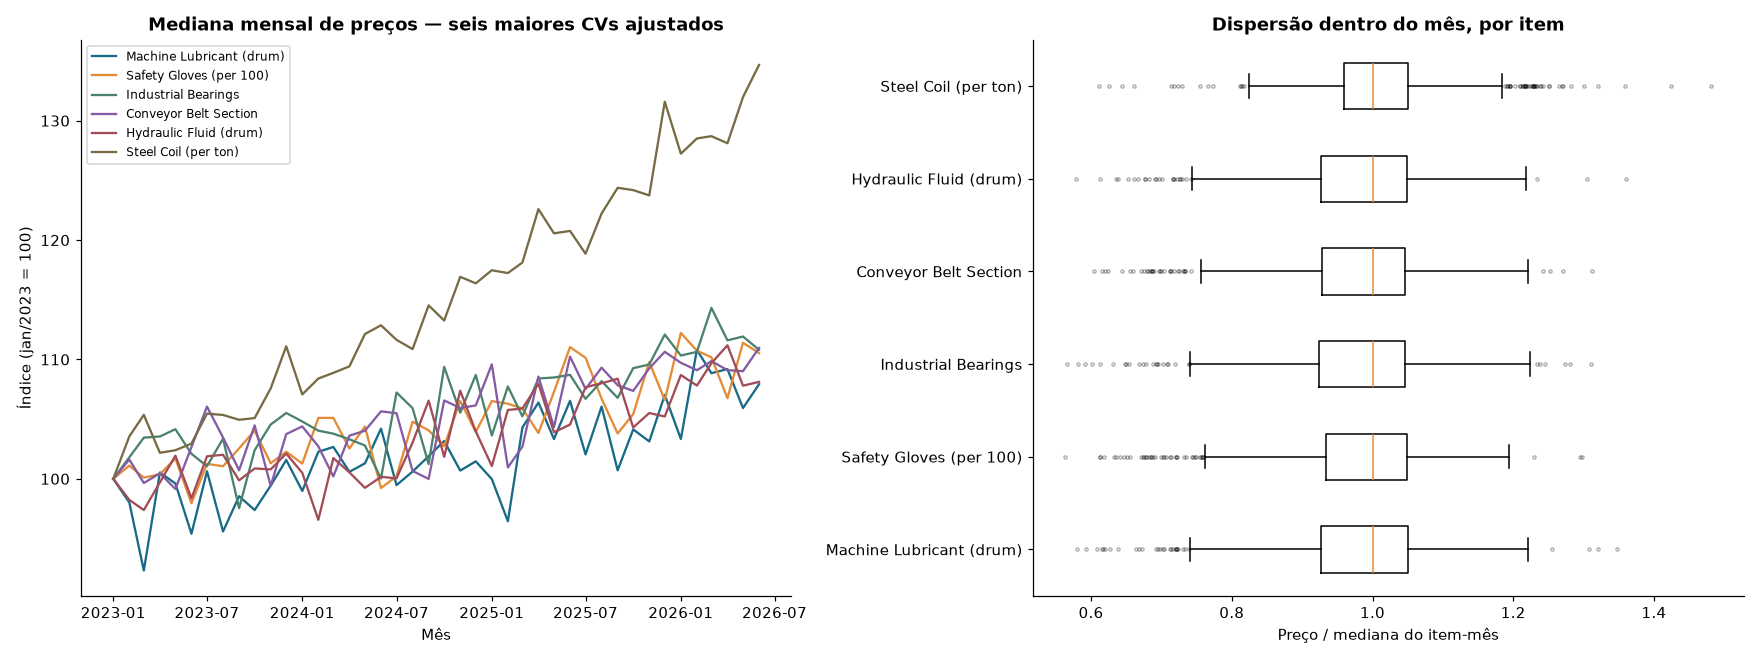

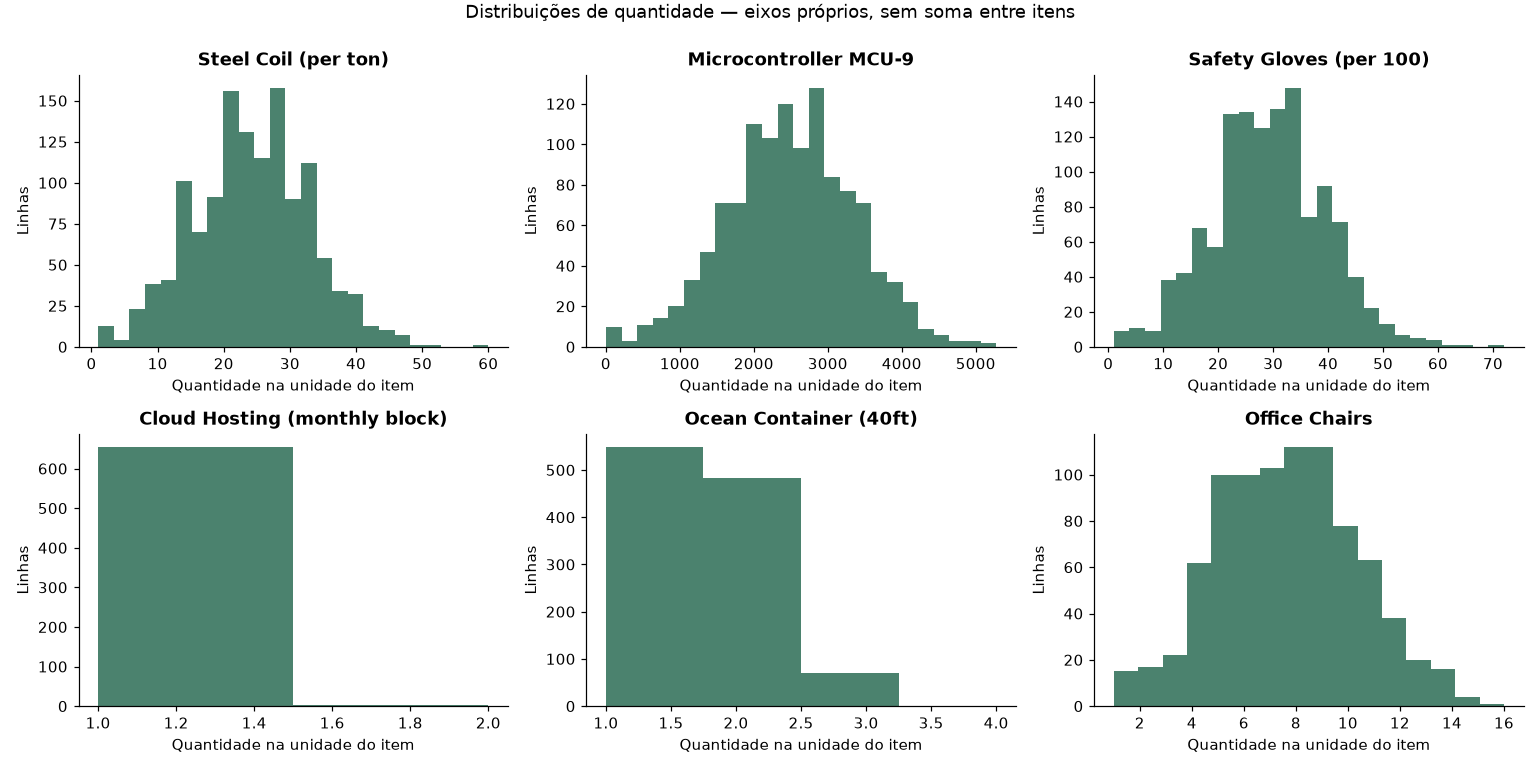

In [6]:
selected_items = volatile_items.head(6).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for item in selected_items:
    series = item_price_wide.loc[item]
    axes[0].plot(series.index.to_timestamp(), series / series.iloc[0] * 100, label=item)
axes[0].set(title="Mediana mensal de preços — seis maiores CVs ajustados",
            ylabel="Índice (jan/2023 = 100)", xlabel="Mês")
axes[0].legend(fontsize=8)
axes[1].boxplot([df.loc[df.item.eq(item), "relative_month_price"] for item in selected_items],
                orientation="horizontal", tick_labels=selected_items, showfliers=True,
                flierprops={"markersize": 2, "alpha": .3})
axes[1].set(title="Dispersão dentro do mês, por item", xlabel="Preço / mediana do item-mês")
show(fig)
quantity_items = ["Steel Coil (per ton)", "Microcontroller MCU-9", "Safety Gloves (per 100)",
                  "Cloud Hosting (monthly block)", "Ocean Container (40ft)", "Office Chairs"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, item in zip(axes.flat, quantity_items, strict=True):
    values = df.loc[df.item.eq(item), "quantity"]
    ax.hist(values, bins=min(25, values.nunique()), color="#4B826E")
    ax.set(title=item, xlabel="Quantidade na unidade do item", ylabel="Linhas")
fig.suptitle("Distribuições de quantidade — eixos próprios, sem soma entre itens", y=.995)
show(fig)

## Fornecedores, categorias e comparação de preços

`supplier_id` é a chave de agrupamento; nomes são apenas rótulos. Volume significa **número de linhas**, não soma de quantidades incompatíveis. As tabelas completas `suppliers`, `supplier_product_prices` e `supplier_month` permanecem disponíveis em memória.

A comparação por fornecedor usa o mesmo item. A mediana do preço relativo ao item-mês reduz a mistura de períodos, mas é retrospectiva e não ajusta frete, impostos, qualidade, contratos ou descontos, inexistentes no CSV.

,concentracao
total_UM,4.111833e+08
top1_pct,2.040753e+01
top5_pct,3.875895e+01
top10_pct,5.355296e+01
suppliers_for_80pct,2.300000e+01
suppliers_under10_lines,7.000000e+00


,name,category,lines,spend,active_months,products,first,last,late_count,late_rate,reject_count,reject_rate,off_contract_rate,mean_delay,lines_per_calendar_month,spend_share,cumulative_spend_share
supplier_id,,,,,,,,,,,,,,,,,
SUP-002,Taegu Alloys,Raw Materials,4172,83912380.83,42,5,2023-01-01,2026-06-30,453,0.1086,61,0.0146,0.1371,0.2579,99.3333,0.2041,0.2041
SUP-016,Great Wall Containers,Packaging,5384,24672186.74,42,5,2023-01-01,2026-06-30,546,0.1014,79,0.0147,0.1478,0.2641,128.1905,0.0600,0.2641
SUP-028,Summit Components,Electronics,1144,21206582.00,42,5,2023-01-02,2026-06-29,129,0.1128,15,0.0131,0.1460,0.2552,27.2381,0.0516,0.3157
SUP-025,Cascade Semitech,Electronics,855,16010733.91,42,5,2023-01-05,2026-06-30,89,0.1041,12,0.0140,0.1322,0.2409,20.3571,0.0389,0.3546
SUP-006,Adler Metals,Raw Materials,581,13568470.46,42,5,2023-01-02,2026-06-24,74,0.1274,16,0.0275,0.1291,0.2874,13.8333,0.0330,0.3876
SUP-008,Fujikawa Resources,Raw Materials,637,12990183.01,42,5,2023-01-04,2026-06-27,611,0.9592,72,0.1130,0.1507,10.6939,15.1667,0.0316,0.4192
SUP-034,Pacific Rim Circuits,Electronics,690,12181112.88,42,5,2023-01-05,2026-06-29,74,0.1072,10,0.0145,0.1681,0.2754,16.4286,0.0296,0.4488
SUP-095,Busan Machinery,Machinery,1353,12149653.63,42,5,2023-01-01,2026-06-30,155,0.1146,21,0.0155,0.1375,0.2676,32.2143,0.0295,0.4784
SUP-036,Golden Dragon Components,Electronics,640,11943662.41,42,5,2023-01-01,2026-06-29,80,0.1250,10,0.0156,0.1312,0.3172,15.2381,0.0290,0.5074


,lines,spend,suppliers,products
category,,,,
Raw Materials,6539,1.355845e+08,10,5
Electronics,6123,1.086383e+08,15,5
Chemicals,4754,2.884948e+07,15,5
Professional Services,3281,2.873491e+07,10,5
Packaging,5706,2.618996e+07,11,5
Logistics,5556,2.556826e+07,10,5
IT Services,3320,2.343901e+07,10,5
MRO,6172,1.730716e+07,10,5
Machinery,1381,1.237089e+07,2,5


,supplier_name,lines,mean_price,median_price,min_price,max_price,median_relative_month_price
supplier_id,,,,,,,
SUP-039,Redwood Maintenance Co,76,162.9036,162.555,142.83,181.18,0.8945
SUP-042,Cascade Maintenance Co,17,163.2071,160.920,146.55,179.62,0.9010
SUP-045,Thames MRO Services,27,165.9148,167.750,150.23,181.37,0.9070
SUP-046,Thames Industrial Supply,372,168.8370,167.865,104.02,243.29,0.9257
SUP-044,Mekong Maintenance Co,61,174.6115,173.900,151.02,195.88,0.9460
SUP-041,Bergmann Maintenance Co,29,182.9017,183.530,164.78,215.22,1.0000
SUP-037,Liberty MRO Services,7,190.8500,186.500,174.22,212.72,1.0237
SUP-038,Bergmann MRO Services,340,190.5007,190.005,164.18,220.24,1.0311
SUP-043,Great Wall Maintenance Co,51,190.2061,188.360,172.06,212.38,1.0338


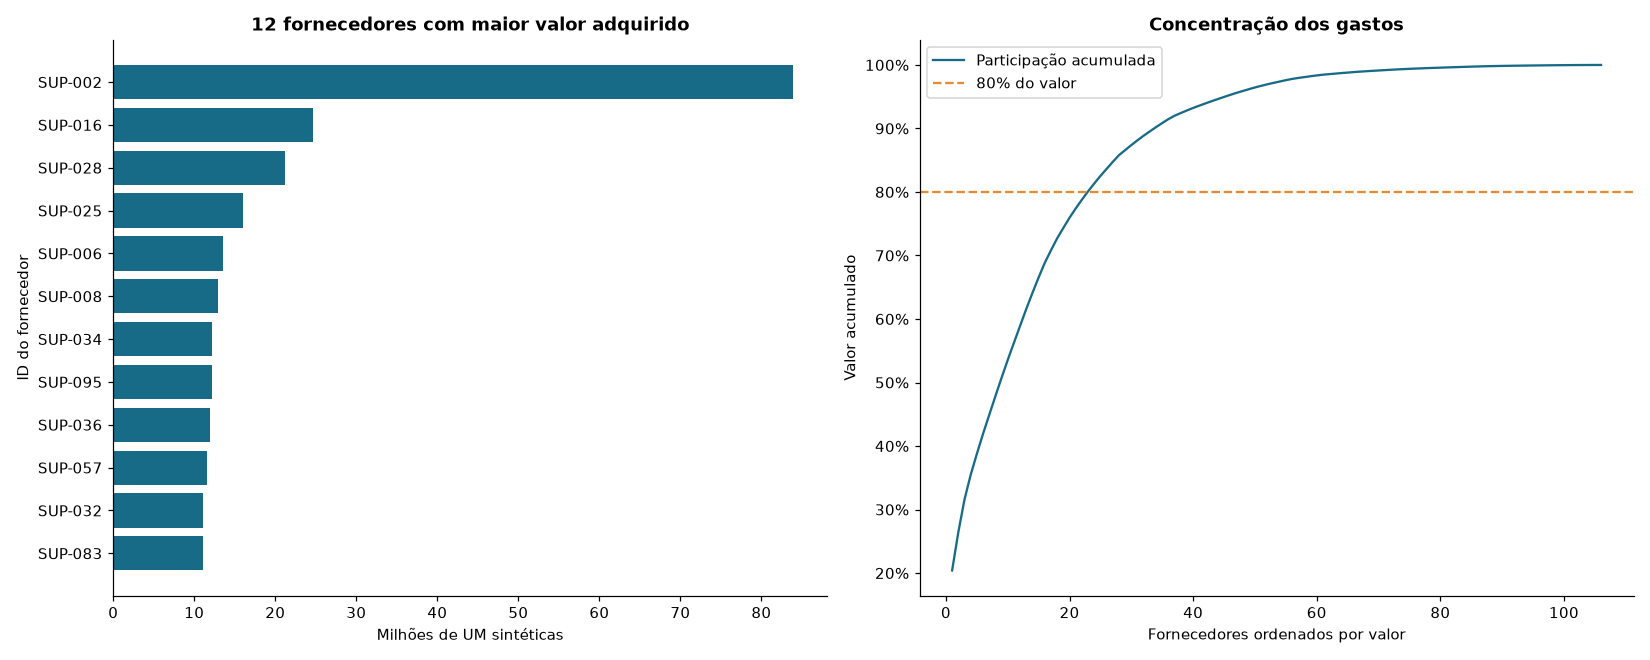

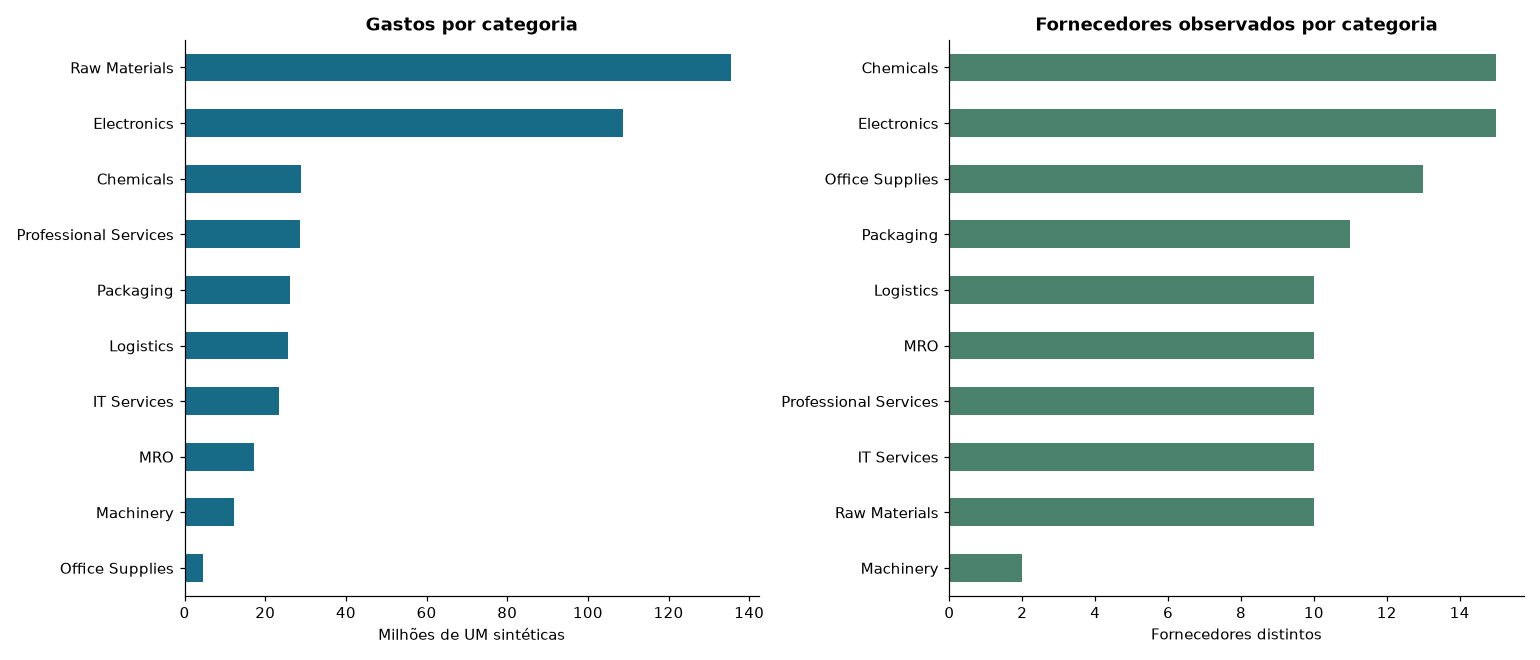

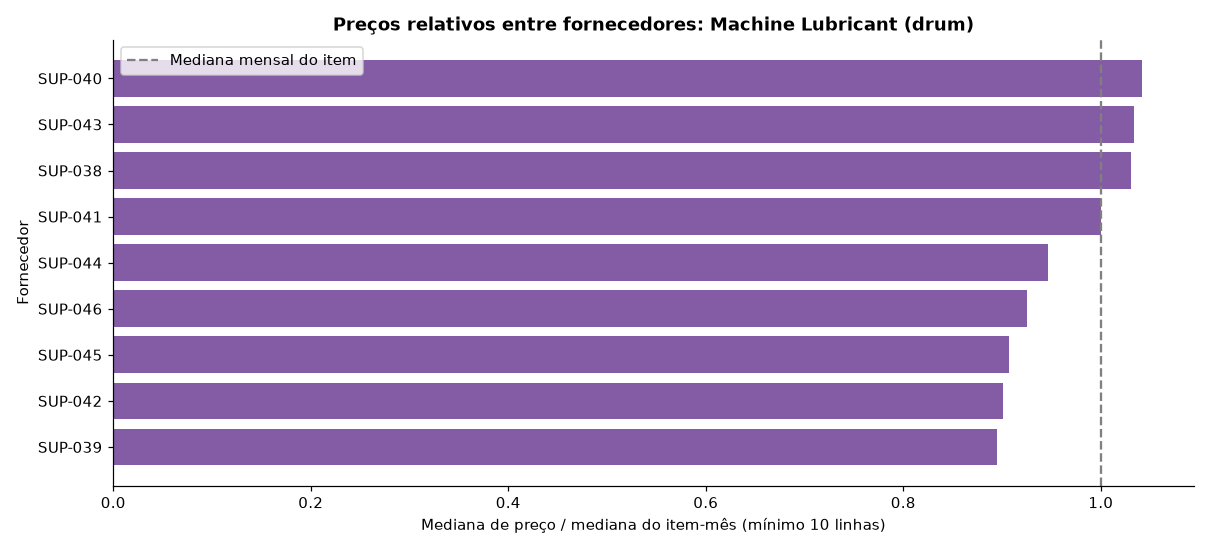

In [7]:
suppliers = df.groupby("supplier_id").agg(
    name=("supplier_name", "first"), category=("category", "first"),
    lines=("po_id", "size"), spend=("line_total", "sum"), active_months=("month", "nunique"),
    products=("item", "nunique"), first=("order_date", "min"), last=("order_date", "max"),
    late_count=("late", "sum"), late_rate=("late", "mean"),
    reject_count=("quality_rejected", "sum"), reject_rate=("quality_rejected", "mean"),
    off_contract_rate=("off_contract", "mean"), mean_delay=("delay_days", "mean"),
)
suppliers["lines_per_calendar_month"] = suppliers["lines"] / df["month"].nunique()
suppliers["spend_share"] = suppliers["spend"] / suppliers["spend"].sum()
suppliers = suppliers.sort_values("spend", ascending=False)
suppliers["cumulative_spend_share"] = suppliers["spend_share"].cumsum()
supplier_product_prices = df.groupby(["item", "supplier_id"]).agg(
    supplier_name=("supplier_name", "first"), lines=("po_id", "size"),
    mean_price=("unit_price", "mean"), median_price=("unit_price", "median"),
    min_price=("unit_price", "min"), max_price=("unit_price", "max"),
    median_relative_month_price=("relative_month_price", "median"),
)
supplier_month = df.groupby(["supplier_id", "month"]).agg(
    lines=("po_id", "size"), spend=("line_total", "sum"),
    late_rate=("late", "mean"), reject_rate=("quality_rejected", "mean"),
)
category_summary = df.groupby("category").agg(
    lines=("po_id", "size"), spend=("line_total", "sum"),
    suppliers=("supplier_id", "nunique"), products=("item", "nunique"),
).sort_values("spend", ascending=False)
concentration = pd.Series({
    "total_UM": suppliers.spend.sum(),
    "top1_pct": 100 * suppliers.spend_share.head(1).sum(),
    "top5_pct": 100 * suppliers.spend_share.head(5).sum(),
    "top10_pct": 100 * suppliers.spend_share.head(10).sum(),
    "suppliers_for_80pct": int(np.searchsorted(suppliers.cumulative_spend_share.to_numpy(), .8) + 1),
    "suppliers_under10_lines": int(suppliers.lines.lt(10).sum()),
}, name="concentracao")
table(concentration.to_frame())
table(suppliers.round(4), 20)
table(category_summary)
comparison_item = volatile_items.index[0]
comparison = supplier_product_prices.loc[comparison_item].sort_values("median_relative_month_price")
table(comparison.round(4))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = suppliers.head(12).iloc[::-1]
axes[0].barh(top.index, top["spend"] / 1e6)
axes[0].set(title="12 fornecedores com maior valor adquirido", xlabel="Milhões de UM sintéticas",
            ylabel="ID do fornecedor")
rank = np.arange(1, len(suppliers) + 1)
axes[1].plot(rank, suppliers.cumulative_spend_share, label="Participação acumulada")
axes[1].axhline(.8, color="#E48B35", linestyle="--", label="80% do valor")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title="Concentração dos gastos", xlabel="Fornecedores ordenados por valor", ylabel="Valor acumulado")
axes[1].legend()
show(fig)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
category_summary.sort_values("spend")["spend"].div(1e6).plot.barh(ax=axes[0], color="#176B87")
axes[0].set(title="Gastos por categoria", xlabel="Milhões de UM sintéticas", ylabel="")
category_summary.sort_values("suppliers")["suppliers"].plot.barh(ax=axes[1], color="#4B826E")
axes[1].set(title="Fornecedores observados por categoria", xlabel="Fornecedores distintos", ylabel="")
show(fig)
fig, ax = plt.subplots(figsize=(11, 5))
supported_comparison = comparison[comparison["lines"].ge(10)]
ax.barh(supported_comparison.index, supported_comparison["median_relative_month_price"], color="#845BA5")
ax.axvline(1, color="gray", linestyle="--", label="Mediana mensal do item")
ax.set(title=f"Preços relativos entre fornecedores: {comparison_item}",
       xlabel="Mediana de preço / mediana do item-mês (mínimo 10 linhas)", ylabel="Fornecedor")
ax.legend()
show(fig)

## Entrega, qualidade e contrato

Taxas exibem também numeradores e denominadores. Fornecedores com pouco histórico podem apresentar percentuais extremos por acaso. O destaque visual usa mínimo de 30 linhas apenas como filtro descritivo declarado, não como regra de negócio ou critério validado de risco.

`actual_delivery_date` e `quality_rejected` são pós-evento. A fonte não registra a data da inspeção de qualidade. Essas colunas não são entradas da própria compra em uma futura análise no instante do pedido. `on_contract` não substitui comprovação de vínculo contratual.

,count,denominator,pct
Fora de contrato,6680,47128,14.174
Entrega atrasada,7700,47128,16.338
Rejeição de qualidade,1029,47128,2.183


,lines,off_contract_count,off_contract_rate,late_rate,reject_rate
business_unit,,,,,
Corporate,9368,439,0.0469,0.1673,0.0236
Field Services,9309,2960,0.3180,0.1733,0.0197
Manufacturing,9401,472,0.0502,0.1631,0.0211
R&D,9624,2339,0.2430,0.1588,0.0215
Retail Operations,9426,470,0.0499,0.1548,0.0233


,name,lines,late_count,late_rate,reject_count,reject_rate,mean_delay,off_contract_rate
supplier_id,,,,,,,,
SUP-063,Cascade Technologies,48,48,1.0000,5,0.1042,10.2083,0.1250
SUP-018,Great Wall Packaging,125,120,0.9600,20,0.1600,10.4400,0.1360
SUP-008,Fujikawa Resources,637,611,0.9592,72,0.1130,10.6939,0.1507
SUP-029,Great Wall Components,384,363,0.9453,42,0.1094,10.8177,0.1458
SUP-046,Thames Industrial Supply,1848,1746,0.9448,216,0.1169,10.4968,0.1380
SUP-078,Baltic Workplace,193,179,0.9275,19,0.0984,11.0052,0.1347
SUP-071,Redwood Supplies Co,41,9,0.2195,0,0.0000,0.5366,0.1220
SUP-026,Great Wall Circuits,63,12,0.1905,1,0.0159,0.4921,0.1429
SUP-019,Adler Packaging,47,8,0.1702,0,0.0000,0.4255,0.0851


Sem entrega efetiva: 0 | Entregas antecipadas: 0
Entregas posteriores ao último pedido: 717


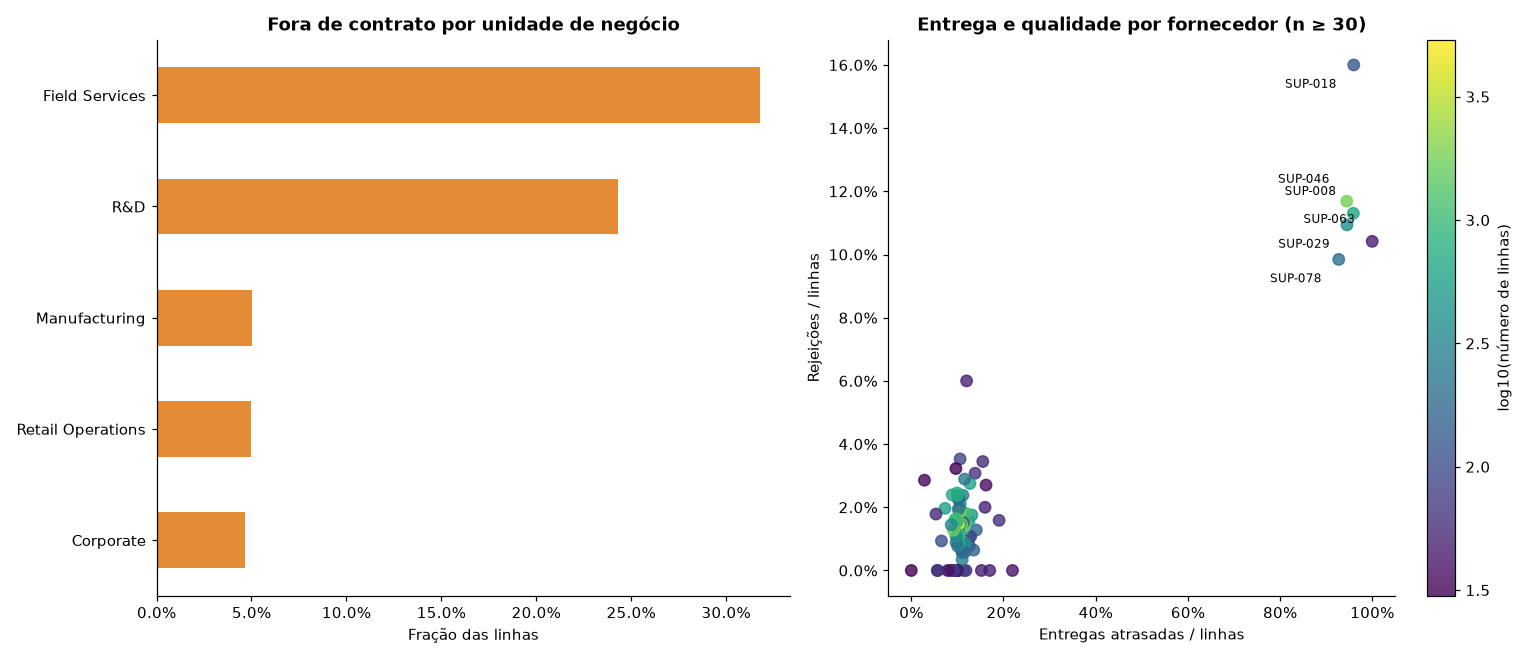

In [8]:
indicators = pd.DataFrame({
    "count": [df.off_contract.sum(), df.late.sum(), df.quality_rejected.sum()],
    "denominator": len(df),
}, index=["Fora de contrato", "Entrega atrasada", "Rejeição de qualidade"])
indicators["pct"] = indicators["count"] / indicators["denominator"] * 100
unit_indicators = df.groupby("business_unit").agg(
    lines=("po_id", "size"), off_contract_count=("off_contract", "sum"),
    off_contract_rate=("off_contract", "mean"), late_rate=("late", "mean"),
    reject_rate=("quality_rejected", "mean"),
)
supported_suppliers = suppliers[suppliers.lines.ge(30)].sort_values("late_rate", ascending=False)
table(indicators.round(3))
table(unit_indicators.round(4))
table(supported_suppliers[["name", "lines", "late_count", "late_rate", "reject_count",
                           "reject_rate", "mean_delay", "off_contract_rate"]].round(4), 15)
print("Sem entrega efetiva:", int(df.actual_delivery_date.isna().sum()),
      "| Entregas antecipadas:", int(df.delay_days.lt(0).sum()))
print("Entregas posteriores ao último pedido:", int(df.actual_delivery_date.gt(df.order_date.max()).sum()))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
unit_indicators.sort_values("off_contract_rate")["off_contract_rate"].plot.barh(ax=axes[0], color="#E48B35")
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(title="Fora de contrato por unidade de negócio", xlabel="Fração das linhas", ylabel="")
points = axes[1].scatter(supported_suppliers.late_rate, supported_suppliers.reject_rate,
                         c=np.log10(supported_suppliers.lines), cmap="viridis", s=55, alpha=.8)
for i, (sid, row) in enumerate(supported_suppliers.head(6).iterrows()):
    axes[1].annotate(sid, (row.late_rate, row.reject_rate),
                     xytext=(-45, 12 if i % 2 == 0 else -15), textcoords="offset points", fontsize=8)
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title="Entrega e qualidade por fornecedor (n ≥ 30)",
            xlabel="Entregas atrasadas / linhas", ylabel="Rejeições / linhas")
fig.colorbar(points, ax=axes[1], label="log10(número de linhas)")
show(fig)

Comparação descritiva 2023Q1 → 2026Q2; mínimo 20 linhas em cada trimestre.


,lines_first,late_rate_first,reject_rate_first,relative_price_median_first,lines_last,late_rate_last,reject_rate_last,relative_price_median_last,late_change_pp,reject_change_pp,relative_price_change
supplier_id,,,,,,,,,,,
SUP-024,24,0.2083,0.0000,1.0012,28,0.0000,0.0357,1.0288,-20.8333,3.5714,0.0276
SUP-036,42,0.0476,0.0238,1.0478,47,0.1915,0.0000,1.0746,14.3870,-2.3810,0.0268
SUP-081,32,0.1250,0.0000,0.8940,27,0.2593,0.0741,0.8884,13.4259,7.4074,-0.0056
SUP-039,30,0.0333,0.0333,0.8905,23,0.1304,0.0000,0.8837,9.7101,-3.3333,-0.0068
SUP-034,52,0.0192,0.0000,0.9854,55,0.0909,0.0182,1.0053,7.1678,1.8182,0.0200
SUP-050,70,0.1143,0.0143,0.9803,63,0.0476,0.0000,0.9849,-6.6667,-1.4286,0.0046
SUP-093,84,0.0476,0.0000,1.0215,105,0.1143,0.0095,1.0144,6.6667,0.9524,-0.0071
SUP-051,156,0.1795,0.0128,0.9980,131,0.1145,0.0076,0.9950,-6.4983,-0.5187,-0.0031
SUP-025,58,0.0517,0.0172,1.0337,52,0.1154,0.0000,1.0321,6.3660,-1.7241,-0.0017


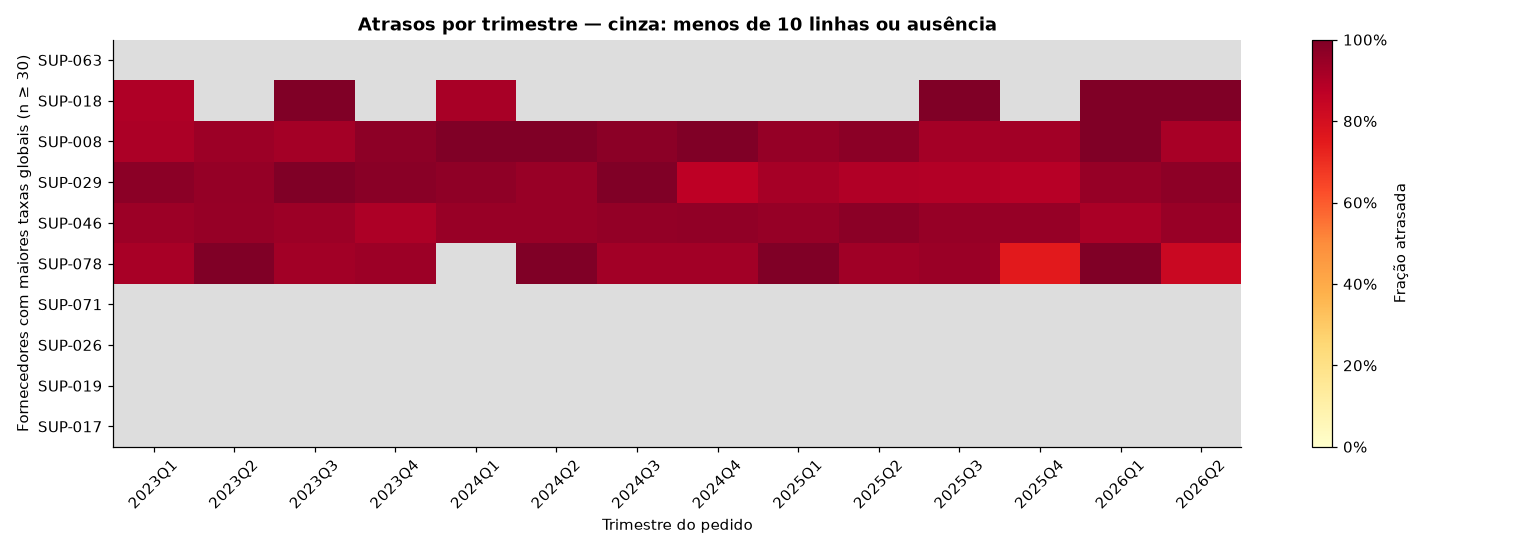

In [9]:
supplier_quarter = df.groupby(["supplier_id", "quarter"]).agg(
    lines=("po_id", "size"), late_rate=("late", "mean"), reject_rate=("quality_rejected", "mean"),
    relative_price_median=("relative_month_price", "median"),
)
first_quarter, last_quarter = df.quarter.min(), df.quarter.max()
changes = supplier_quarter.xs(first_quarter, level="quarter").add_suffix("_first").join(
    supplier_quarter.xs(last_quarter, level="quarter").add_suffix("_last"), how="inner")
changes = changes[changes.lines_first.ge(20) & changes.lines_last.ge(20)].copy()
changes["late_change_pp"] = 100 * (changes.late_rate_last - changes.late_rate_first)
changes["reject_change_pp"] = 100 * (changes.reject_rate_last - changes.reject_rate_first)
changes["relative_price_change"] = changes.relative_price_median_last - changes.relative_price_median_first
changes = changes.loc[changes.late_change_pp.abs().sort_values(ascending=False).index]
print(f"Comparação descritiva {first_quarter} → {last_quarter}; mínimo 20 linhas em cada trimestre.")
table(changes.round(4), 12)
heat_ids = supported_suppliers.head(10).index
rate_heat = supplier_quarter["late_rate"].unstack("quarter").reindex(heat_ids)
count_heat = supplier_quarter["lines"].unstack("quarter").reindex(heat_ids)
rate_heat = rate_heat.where(count_heat.ge(10))
fig, ax = plt.subplots(figsize=(14, 5))
cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("#dddddd")
im = ax.imshow(rate_heat.to_numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set(xticks=np.arange(len(rate_heat.columns)), xticklabels=[str(q) for q in rate_heat.columns],
       yticks=np.arange(len(rate_heat)), yticklabels=rate_heat.index,
       title="Atrasos por trimestre — cinza: menos de 10 linhas ou ausência",
       xlabel="Trimestre do pedido", ylabel="Fornecedores com maiores taxas globais (n ≥ 30)")
ax.tick_params(axis="x", rotation=45)
fig.colorbar(im, ax=ax, format=PercentFormatter(1), label="Fração atrasada")
show(fig)

## Extremos estatísticos contra histórico estritamente anterior

Convenção exploratória declarada antes da contagem:
- Grupo: mesmo `item`, sem somar unidades físicas diferentes.
- Referência: pedidos em **[t − 90 dias, t)**; nenhuma linha do dia atual participa.
- Suporte mínimo: **20 linhas históricas**.
- Preço/total altos: acima de Q3 + 1,5 × IQR. Quantidade: fora de [Q1 − 1,5 × IQR, Q3 + 1,5 × IQR].
- Também mostramos sensibilidade com 3 × IQR. Não selecionamos o corte com base em uma label.
- MAD: mediana de |x − mediana|. A distância apresentada é em unidades de MAD, sem interpretação probabilística.
- IQR ou MAD zero e histórico insuficiente produzem **indisponibilidade**, não normalidade.

Essas regras produzem candidatos para investigação, não fraude, classificação de risco ou validação de um modelo. A janela e os cortes não ficam congelados para P5.5 por esta EDA. Os testes pequenos abaixo verificam exclusão do próprio dia, fronteira da janela e cálculo dos quartis.

In [10]:
WINDOW_DAYS = 90
MIN_HISTORY = 20

def prior_item_statistics(frame, window_days=WINDOW_DAYS, min_history=MIN_HISTORY):
    """Estatísticas descritivas em memória; referência [t-window, t), por item."""
    metrics = ("unit_price", "quantity", "line_total")
    columns = ["n_prior"] + [f"{metric}_{stat}" for metric in metrics for stat in ("q1", "median", "q3", "mad")]
    result = pd.DataFrame(np.nan, index=frame.index, columns=columns)
    for _, group in frame.groupby("item", sort=True):
        group = group.sort_values(["order_date", "po_id"])
        days = group.order_date.to_numpy().astype("datetime64[D]").astype(np.int64)
        values = group[list(metrics)].to_numpy(dtype=float)
        for day in np.unique(days):
            left = int(np.searchsorted(days, day - window_days, side="left"))
            right = int(np.searchsorted(days, day, side="left"))
            positions = group.index[days == day]
            result.loc[positions, "n_prior"] = right - left
            if right - left < min_history:
                continue
            history_values = values[left:right]
            quartiles = np.quantile(history_values, [.25, .5, .75], axis=0)
            mad = np.median(np.abs(history_values - quartiles[1]), axis=0)
            stats = np.column_stack((quartiles.T, mad)).ravel()
            result.loc[positions, columns[1:]] = np.tile(stats, (len(positions), 1))
    return result

probe = pd.DataFrame({
    "po_id": ["a", "b", "c", "d", "e", "f"],
    "item": ["X", "X", "X", "X", "X", "Y"],
    "order_date": pd.to_datetime(["2024-01-01", "2024-01-02", "2024-01-03", "2024-01-03", "2024-01-04", "2024-01-03"]),
    "unit_price": [10, 20, 999, 888, 30, 777],
    "quantity": [10, 20, 999, 888, 30, 777],
    "line_total": [10, 20, 999, 888, 30, 777],
})
probe_stats = prior_item_statistics(probe, window_days=2, min_history=2)
assert probe_stats.loc[2, "n_prior"] == probe_stats.loc[3, "n_prior"] == 2
assert probe_stats.loc[2, "unit_price_median"] == 15
assert probe_stats.loc[2, "unit_price_q1"] == 12.5
assert probe_stats.loc[2, "unit_price_q3"] == 17.5
assert probe_stats.loc[2, "unit_price_mad"] == 5
assert probe_stats.loc[4, "n_prior"] == 3  # Jan 1 excluído, Jan 2 incluído.
assert probe_stats.loc[5, "n_prior"] == 0 and pd.isna(probe_stats.loc[5, "unit_price_median"])
constant_probe = probe.assign(unit_price=10)
assert prior_item_statistics(constant_probe, 2, 2).loc[2, "unit_price_mad"] == 0
print("Verificações sintéticas da janela: aprovadas.")

Verificações sintéticas da janela: aprovadas.


,signal,IQR_multiplier,eligible,insufficient_history,zero_IQR_with_history,flagged,pct_of_eligible
0,Preço alto,1.5,45445,1683,0,782,1.721
1,Preço alto,3.0,45445,1683,0,59,0.130
2,Quantidade incomum,1.5,40572,1683,4873,610,1.503
3,Quantidade incomum,3.0,40572,1683,4873,9,0.022
4,Total alto,1.5,45445,1683,0,468,1.030
5,Total alto,3.0,45445,1683,0,17,0.037


,po_id,order_date,item,supplier_id,unit_price,quantity,line_total,n_prior,unit_price_median,unit_price_vs_prior_median,unit_price_mad_distance
36931,PO-2025-36725,2025-10-06,Steel Coil (per ton),SUP-008,1391.58,20,27831.60,94.0,928.725,1.4984,10.3954
6949,PO-2023-06543,2023-07-16,Copper Wire Rod (per ton),SUP-008,12873.24,3,38619.72,91.0,8874.020,1.4507,10.0203
41289,PO-2026-41074,2026-01-17,Microcontroller MCU-9,SUP-029,14.57,3333,48561.81,102.0,10.095,1.4433,6.6791
2641,PO-2023-02358,2023-03-18,PCB Assembly A-11,SUP-029,71.55,366,26187.30,70.0,49.735,1.4386,9.4233
28633,PO-2025-28249,2025-02-12,Steel Coil (per ton),SUP-008,1262.96,28,35362.88,105.0,887.960,1.4223,8.1913
34412,PO-2025-33469,2025-07-31,Rubber Compound (per ton),SUP-008,2661.44,9,23952.96,73.0,1875.590,1.4190,10.5540
25205,PO-2024-24474,2024-11-18,Copper Wire Rod (per ton),SUP-008,13793.91,3,41381.73,100.0,9858.495,1.3992,8.5831
31455,PO-2025-31284,2025-05-05,Copper Wire Rod (per ton),SUP-008,14181.70,1,14181.70,81.0,10263.610,1.3817,7.8031
31360,PO-2025-31256,2025-05-03,Steel Coil (per ton),SUP-008,1239.63,37,45866.31,96.0,897.610,1.3810,8.5281
39849,PO-2025-39823,2025-12-10,Microcontroller MCU-9,SUP-029,13.75,1491,20501.25,101.0,9.970,1.3791,5.7273


,po_id,item,quantity,quantity_median,quantity_vs_prior_median,n_prior
35872,PO-2025-35618,Copper Wire Rod (per ton),6,2.0,3.0000,99.0
18594,PO-2024-18099,Aluminium Sheet (per ton),21,7.0,3.0000,95.0
28566,PO-2025-28794,FTL Freight (per load),8,3.0,2.6667,91.0
8756,PO-2023-09146,FTL Freight (per load),8,3.0,2.6667,72.0
21260,PO-2024-21714,Network Equipment Bundle,4,1.5,2.6667,32.0
23663,PO-2024-23071,Steel Coil (per ton),60,23.0,2.6087,82.0
41666,PO-2026-40886,Aluminium Sheet (per ton),18,7.0,2.5714,102.0
31107,PO-2025-30359,Copper Wire Rod (per ton),5,2.0,2.5000,86.0
30756,PO-2025-30327,Copper Wire Rod (per ton),5,2.0,2.5000,84.0
4231,PO-2023-03293,Copper Wire Rod (per ton),5,2.0,2.5000,114.0


,po_id,item,line_total,line_total_median,line_total_vs_prior_median,n_prior
18594,PO-2024-18099,Aluminium Sheet (per ton),64537.41,18558.470,3.4775,95.0
21260,PO-2024-21714,Network Equipment Bundle,13259.56,4572.435,2.8999,32.0
20768,PO-2024-20506,Industrial Bearings,7071.36,2492.040,2.8376,83.0
4231,PO-2023-03293,Copper Wire Rod (per ton),56412.50,20397.180,2.7657,114.0
23663,PO-2024-23071,Steel Coil (per ton),51053.40,18926.265,2.6975,82.0
44653,PO-2026-43985,Copper Wire Rod (per ton),64015.05,23908.340,2.6775,93.0
12677,PO-2023-13026,Industrial Bearings,6850.26,2579.355,2.6558,106.0
5950,PO-2023-05859,Conveyor Belt Section,6662.64,2565.250,2.5973,73.0
40377,PO-2025-40227,Air Freight (per 100kg),7554.10,2923.460,2.5840,94.0
31107,PO-2025-30359,Copper Wire Rod (per ton),62266.05,24228.570,2.5699,86.0


Linhas com os três sinais disponíveis e simultâneos: 9


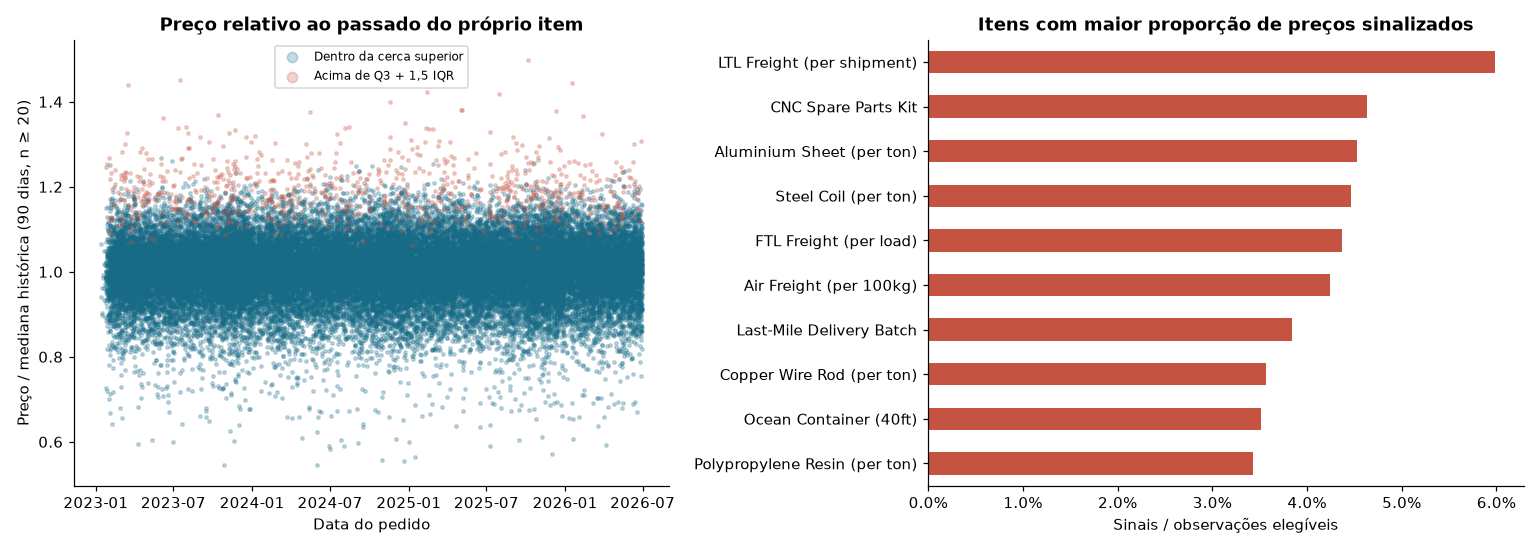

In [11]:
history_stats = prior_item_statistics(df)
investigation = df.join(history_stats)
anomaly_counts = []
for metric, label in (("unit_price", "Preço alto"), ("quantity", "Quantidade incomum"),
                       ("line_total", "Total alto")):
    iqr = investigation[f"{metric}_q3"] - investigation[f"{metric}_q1"]
    eligible = investigation["n_prior"].ge(MIN_HISTORY) & iqr.gt(0)
    investigation[f"{metric}_eligible"] = eligible
    for multiplier in (1.5, 3.0):
        flagged = investigation[metric].gt(investigation[f"{metric}_q3"] + multiplier * iqr)
        if metric == "quantity":
            flagged |= investigation[metric].lt(investigation[f"{metric}_q1"] - multiplier * iqr)
        key = f"{metric}_flag_{multiplier}"
        investigation[key] = flagged.astype("boolean").where(eligible, pd.NA)
        anomaly_counts.append({
            "signal": label, "IQR_multiplier": multiplier, "eligible": int(eligible.sum()),
            "insufficient_history": int(investigation.n_prior.lt(MIN_HISTORY).sum()),
            "zero_IQR_with_history": int((investigation.n_prior.ge(MIN_HISTORY) & iqr.eq(0)).sum()),
            "flagged": int(investigation[key].sum()),
            "pct_of_eligible": 100 * investigation[key].sum() / eligible.sum(),
        })
    mad = investigation[f"{metric}_mad"]
    investigation[f"{metric}_mad_distance"] = (
        (investigation[metric] - investigation[f"{metric}_median"]) / mad.where(mad.gt(0)))
    investigation[f"{metric}_vs_prior_median"] = (
        investigation[metric] / investigation[f"{metric}_median"])
anomaly_summary = pd.DataFrame(anomaly_counts)
table(anomaly_summary.round(3))
flag_columns = [f"{metric}_flag_1.5" for metric in ("unit_price", "quantity", "line_total")]
price_candidates = investigation[investigation["unit_price_flag_1.5"].fillna(False)].sort_values(
    "unit_price_vs_prior_median", ascending=False)
candidate_columns = ["po_id", "order_date", "item", "supplier_id", "unit_price", "quantity", "line_total",
                     "n_prior", "unit_price_median", "unit_price_vs_prior_median", "unit_price_mad_distance"]
table(price_candidates[candidate_columns].round(4), 15)
quantity_candidates = investigation[investigation["quantity_flag_1.5"].fillna(False)].sort_values(
    "quantity_vs_prior_median", ascending=False)
table(quantity_candidates[["po_id", "item", "quantity", "quantity_median",
                            "quantity_vs_prior_median", "n_prior"]].round(4), 15)
total_candidates = investigation[investigation["line_total_flag_1.5"].fillna(False)].sort_values(
    "line_total_vs_prior_median", ascending=False)
table(total_candidates[["po_id", "item", "line_total", "line_total_median",
                        "line_total_vs_prior_median", "n_prior"]].round(4), 15)
print("Linhas com os três sinais disponíveis e simultâneos:",
      int(investigation[flag_columns].fillna(False).all(axis=1).sum()))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
eligible_price = investigation[investigation["unit_price_eligible"]]
for flagged, color, label in ((False, "#176B87", "Dentro da cerca superior"),
                               (True, "#C45342", "Acima de Q3 + 1,5 IQR")):
    subset = eligible_price[eligible_price["unit_price_flag_1.5"].eq(flagged)]
    axes[0].scatter(subset.order_date, subset.unit_price_vs_prior_median,
                    s=5, alpha=.25, color=color, label=label, rasterized=True)
axes[0].set(title="Preço relativo ao passado do próprio item", xlabel="Data do pedido",
            ylabel="Preço / mediana histórica (90 dias, n ≥ 20)")
axes[0].legend(markerscale=3, fontsize=8)
item_flags = investigation.groupby("item").agg(
    eligible=("unit_price_eligible", "sum"), flagged=("unit_price_flag_1.5", "sum"))
item_flags["rate"] = item_flags.flagged / item_flags.eligible
item_flags.sort_values("rate").tail(10)["rate"].plot.barh(ax=axes[1], color="#C45342")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title="Itens com maior proporção de preços sinalizados",
            xlabel="Sinais / observações elegíveis", ylabel="")
show(fig)

## Compras semelhantes em períodos próximos
Critério exploratório: mesmo fornecedor, item, quantidade e valor total; diferença de até **três dias**, incluindo o mesmo dia. Enumeramos pares únicos, sem excluir linhas. O critério pode identificar repetição legítima e não comprova faturamento ou pagamento duplicado.

Separadamente, conferimos a assinatura das 40 cópias descritas no gerador: todos os campos originais iguais, exceto ID e data do pedido, com deslocamento de 1–2 dias e novos contadores de ID. Essa checagem utiliza conhecimento da simulação; **não é uma descoberta independente nem uma label empresarial**. IDs artificiais não devem ser features.

Pares próximos: 41 | Linhas distintas envolvidas: 82
Pares compatíveis com as cópias documentadas: 40 | IDs novos distintos: 40


,earlier_id,later_id,earlier_date,later_date,gap_days,supplier_id,item,quantity,line_total,same_other_fields_and_shift_1_2,later_in_last40_ids
0,PO-2024-20121,PO-2024-47112,2024-07-04,2024-07-06,2,SUP-002,Aluminium Sheet (per ton),8,21427.20,True,True
1,PO-2025-33470,PO-2025-47092,2025-07-12,2025-07-14,2,SUP-002,Polypropylene Resin (per ton),9,12759.57,True,True
2,PO-2026-43851,PO-2026-47114,2026-04-24,2026-04-25,1,SUP-002,Rubber Compound (per ton),8,15424.16,True,True
3,PO-2025-36813,PO-2025-47121,2025-10-15,2025-10-17,2,SUP-002,Rubber Compound (per ton),9,17539.47,True,True
4,PO-2023-08583,PO-2023-47089,2023-09-11,2023-09-13,2,SUP-002,Steel Coil (per ton),25,19845.75,True,True
5,PO-2023-07526,PO-2023-47106,2023-08-19,2023-08-20,1,SUP-002,Steel Coil (per ton),38,29654.82,True,True
6,PO-2024-23060,PO-2024-47119,2024-10-11,2024-10-12,1,SUP-006,Polypropylene Resin (per ton),17,24614.64,True,True
7,PO-2025-33475,PO-2025-47123,2025-07-08,2025-07-10,2,SUP-006,Steel Coil (per ton),25,26008.50,True,True
8,PO-2025-39395,PO-2025-47104,2025-12-24,2025-12-25,1,SUP-009,Aluminium Sheet (per ton),7,19469.10,True,True
9,PO-2023-08666,PO-2023-47111,2023-09-29,2023-09-30,1,SUP-016,Corrugated Boxes (per 1000),14,9556.68,True,True


Prazo prometido inferior aos cinco dias mínimos do gerador original:


,po_id,order_date,promised_delivery_date,planned_days
24644,PO-2024-47108,2024-11-06,2024-11-10,4
25628,PO-2024-47091,2024-11-26,2024-11-29,3


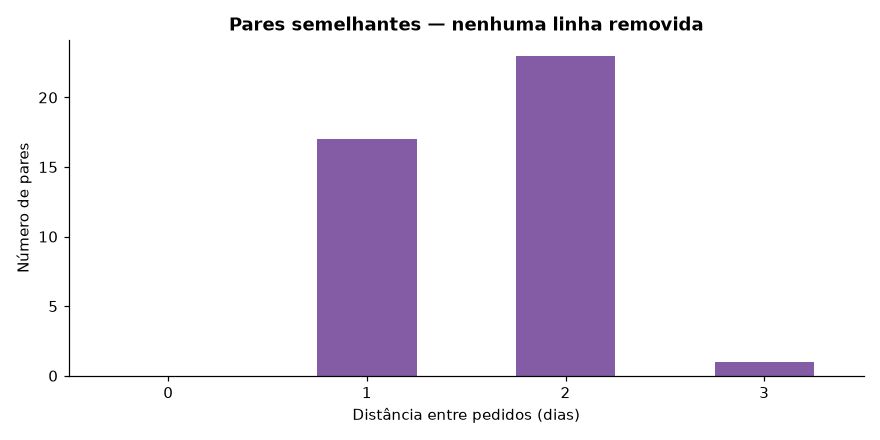

In [12]:
duplicate_keys = ["supplier_id", "item", "quantity", "line_total"]
pairs = []
for _, group in df.groupby(duplicate_keys, sort=True):
    if len(group) < 2:
        continue
    ordered = group.sort_values(["order_date", "po_id"])
    records = list(ordered.itertuples())
    for i, earlier in enumerate(records):
        for later in records[i + 1:]:
            gap = (later.order_date - earlier.order_date).days
            if gap > 3:
                break
            pairs.append({
                "earlier_id": earlier.po_id, "later_id": later.po_id,
                "earlier_date": earlier.order_date, "later_date": later.order_date,
                "gap_days": gap, "supplier_id": earlier.supplier_id, "item": earlier.item,
                "quantity": earlier.quantity, "line_total": earlier.line_total,
            })
near_pairs = pd.DataFrame(pairs)
raw_by_id = raw.set_index("po_id")
signature_columns = [c for c in raw.columns if c not in ("po_id", "order_date")]
matched_generator_pattern = []
for pair in near_pairs.itertuples():
    matched_generator_pattern.append(
        pair.gap_days in (1, 2)
        and raw_by_id.loc[pair.earlier_id, signature_columns].equals(
            raw_by_id.loc[pair.later_id, signature_columns])
    )
near_pairs["same_other_fields_and_shift_1_2"] = matched_generator_pattern
id_counters = df.po_id.str.extract(r"^PO-\d{4}-(\d+)$")[0].astype(int)
last40_ids = set(df.loc[id_counters.gt(id_counters.max() - 40), "po_id"])
near_pairs["later_in_last40_ids"] = near_pairs.later_id.isin(last40_ids)
planted_signature = near_pairs[
    near_pairs.same_other_fields_and_shift_1_2 & near_pairs.later_in_last40_ids]
print("Pares próximos:", len(near_pairs),
      "| Linhas distintas envolvidas:", len(set(near_pairs.earlier_id) | set(near_pairs.later_id)))
print("Pares compatíveis com as cópias documentadas:", len(planted_signature),
      "| IDs novos distintos:", planted_signature.later_id.nunique())
table(near_pairs)
print("Prazo prometido inferior aos cinco dias mínimos do gerador original:")
table(df.loc[df.planned_days.lt(5),
             ["po_id", "order_date", "promised_delivery_date", "planned_days"]])
assert len(planted_signature) == 40 and planted_signature.later_id.is_unique
assert set(planted_signature.later_id) == last40_ids
fig, ax = plt.subplots(figsize=(8, 4))
near_pairs.gap_days.value_counts().reindex(range(4), fill_value=0).sort_index().plot.bar(
    ax=ax, color="#845BA5", rot=0)
ax.set(title="Pares semelhantes — nenhuma linha removida",
       xlabel="Distância entre pedidos (dias)", ylabel="Número de pares")
show(fig)

## Correlações descritivas
Preço e total estão ligados pela identidade `line_total = unit_price × quantity`. Para não comparar quantidades físicas incompatíveis, usamos a quantidade relativa à mediana do mesmo item. Incluímos o preço relativo ao item-mês, prazos e indicadores binários.

Pearson descreve associação linear; Spearman, associação entre ordens. Ambos permanecem confundidos pela mistura de itens, fornecedores e regras do gerador. Não demonstram causalidade, fraude, capacidade preditiva ou disponibilidade temporal. Normalizações que usam o período completo servem somente à descrição.

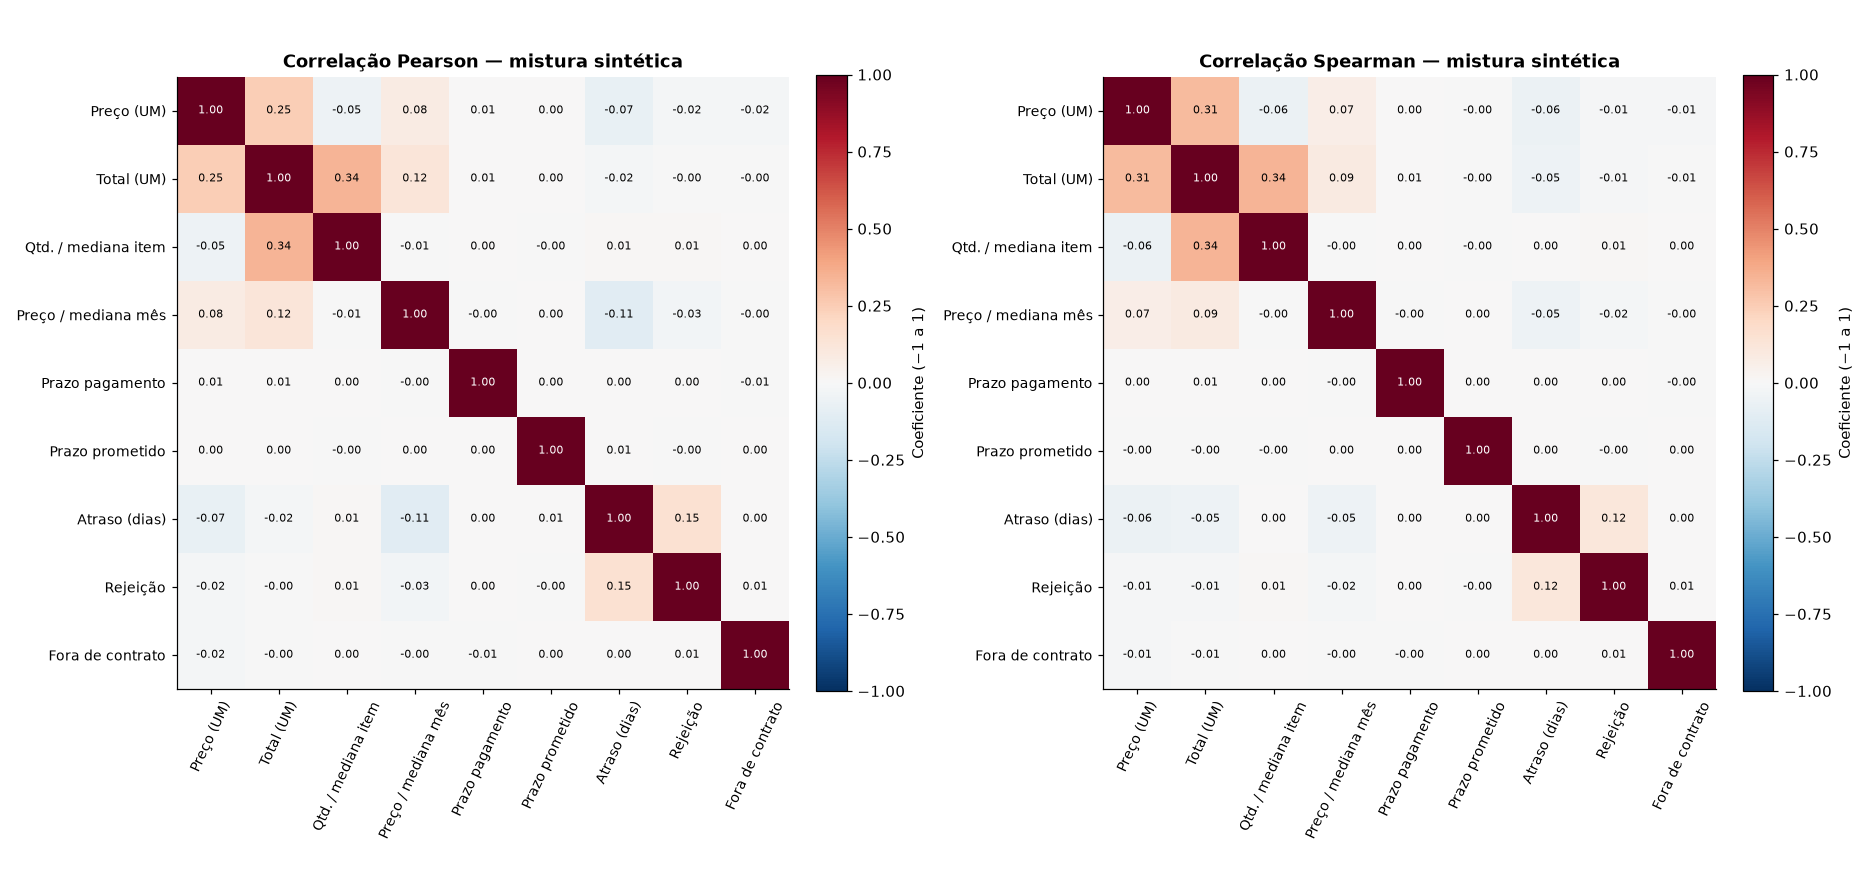

In [13]:
correlation_columns = [
    "unit_price", "line_total", "quantity_relative_item", "relative_month_price",
    "payment_days", "planned_days", "delay_days", "quality_rejected", "off_contract",
]
correlation_labels = [
    "Preço (UM)", "Total (UM)", "Qtd. / mediana item", "Preço / mediana mês",
    "Prazo pagamento", "Prazo prometido", "Atraso (dias)", "Rejeição", "Fora de contrato",
]
correlation_input = df[correlation_columns].astype(float)
correlations = {method: correlation_input.corr(method=method) for method in ("pearson", "spearman")}
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for ax, (method, matrix) in zip(axes, correlations.items(), strict=True):
    im = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set(xticks=range(len(matrix)), xticklabels=correlation_labels,
           yticks=range(len(matrix)), yticklabels=correlation_labels,
           title=f"Correlação {method.title()} — mistura sintética")
    ax.tick_params(axis="x", rotation=65, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            value = matrix.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(value) > .6 else "black")
    fig.colorbar(im, ax=ax, fraction=.046, pad=.04, label="Coeficiente (−1 a 1)")
show(fig)

## Leitura dos resultados

Valores percentuais abaixo estão arredondados; as tabelas e variáveis conservam maior precisão.

**Qualidade e cobertura.** São 47.128 linhas, 16 colunas, 106 fornecedores, 50 itens e 42 meses, de janeiro/2023 a junho/2026. Nenhum nulo, ID repetido, duplicata integral ou divergência decimal em preço × quantidade foi encontrado. Isso confirma consistência interna, sem certificar representatividade real. 2026 contém seis meses. Sete fornecedores têm menos de dez linhas.

**Preços e quantidades.** Após normalização pela mediana do item-mês, os maiores CVs são Machine Lubricant (drum), 10,27%; Safety Gloves (per 100), 10,12%; Industrial Bearings, 9,87%; Conveyor Belt Section, 9,87%; Hydraulic Fluid (drum), 9,80%. São dispersões retrospectivas relativas, não variações percentuais entre duas datas nem scores. Inflação afeta o CV bruto; por exemplo, a mediana de Steel Coil sobe 34,67% entre janeiro/2023 e junho/2026. Itens comprados tipicamente em uma unidade têm distribuições discretas muito concentradas.

**Fornecedores.** SUP-002 representa 20,41% do valor e os dez maiores, 53,55%; 23 fornecedores acumulam pelo menos 80%. As maiores taxas de atraso com n ≥ 30 aparecem em SUP-063, SUP-018, SUP-008, SUP-029, SUP-046 e SUP-078. SUP-063 tem 48/48 entregas atrasadas; SUP-046 tem 1.748/1.848 (94,48%). Os tamanhos diferentes importam. A persistência visual desses perfis é compatível com a regra do gerador, mas esta EDA não recupera uma label latente nem comprova risco real. Variações trimestrais não demonstram mudança estrutural: o perfil gerado é fixo e parte da oscilação pode ser amostral.

**Tempo e indicadores.** No perfil de 2023–2025, novembro tem frequência 26,70% acima da média mensal do próprio ano, em média; outubro/dezembro também sobem. Março apresenta aumento menor. Essas regras já estavam no gerador. Há 6.680 linhas fora de contrato (14,17%), 7.700 atrasadas (16,34%) e 1.029 rejeitadas (2,18%). As entregas chegam a agosto/2026; 717 ocorrem depois do último pedido do CSV. Não há pedidos abertos nem entregas antecipadas.

**Extremos para investigar.** Com janela anterior de 90 dias e mínimo de 20 observações, a cerca de 1,5 IQR marca 782 preços altos em 45.445 elegíveis (1,72%), 610 quantidades incomuns em 40.572 (1,50%) e 468 totais altos em 45.445 (1,03%). Com 3 IQR, as contagens caem para 59, 9 e 17. Isso evidencia sensibilidade ao critério, não acurácia. Há 1.683 linhas sem suporte mínimo; para quantidade, outras 4.873 têm IQR zero apesar do suporte. Nove linhas apresentam os três sinais simultaneamente.

Exemplo rastreável: PO-2025-36725, Steel Coil, SUP-008, preço de 1.391,58 UM frente à mediana anterior de 928,725 UM, com 94 observações. A razão é aproximadamente 1,4984. É um extremo estatístico compatível com o ruído da simulação; não comprova sobrepreço ilícito.

**Semelhanças.** São 41 pares em até três dias, envolvendo 82 linhas. Quarenta correspondem à assinatura das cópias programadas. O par adicional não recebe automaticamente essa classificação. Duas cópias encurtam o prazo prometido para menos dos cinco dias mínimos da geração original. O CSV permanece intacto.

**Hipóteses ainda abertas.** Quanto dos extremos de preço reflete posição habitual do fornecedor versus ruído pontual? A janela de 90 dias é suficiente para cada item e fornecedor? Qual tratamento de suporte baixo e dispersão zero será apropriado? Estas são decisões de P5.5; nenhum método ou threshold de modelo foi selecionado aqui.

## Limitações e direção para P5.5
- Fonte inteiramente sintética, com catálogo e perfis fixos. Recuperar os padrões plantados não comprova desempenho em compras reais. Não há label independente de fraude ou de anomalia.
- Moeda não especificada; não há conversão, imposto, frete, desconto ou catálogo operacional de unidades. Comparações financeiras são internas à simulação.
- `po_id` identifica linhas únicas; não há cabeçalho comprovado, timestamp de aprovação ou histórico de alterações. `order_date` não comprova disponibilidade pré-aprovação.
- A entrega foi preenchida para todas as compras, inclusive após o último pedido. Rejeições não têm data de inspeção. Futuras taxas históricas de atraso devem usar somente desfechos conhecidos no corte; taxas de qualidade exigem definir sua disponibilidade antes de usá-las.
- Pouco suporte em alguns fornecedores e pares fornecedor–item. Uma taxa extrema com poucos casos não justifica rotular um fornecedor.
- Quantidades discretas próximas de 1 geram MAD/IQR zero. Preservar indisponibilidade e suporte; não inventar um desvio para produzir score.
- As 40 cópias e seus deslocamentos preservam campos de entrega e podem encurtar artificialmente o prazo prometido. Nada foi removido ou corrigido.
- A EDA observou todo o CSV: nenhuma parte dele pode ser apresentada depois como teste cego intocado. Um corte temporal futuro será uma avaliação retrospectiva exploratória; independência exigiria uma nova fonte/reserva não examinada.
- Não há ligação com as entidades do formulário V1, nem equivalência com suas 19 features.

**Próxima etapa recomendada:** definir um contrato V2 próprio para a linha de compra no instante do pedido, com moeda/unidade, janela histórica, suporte mínimo e semântica de ausência. Candidatas: razões de preço/quantidade/valor contra medianas passadas do mesmo item; dispersão IQR/MAD e suporte; diferença de preço entre fornecedores no mesmo item e período anterior; frequência/recência e concentração passadas; indicador de contrato sem interpretação de fraude; sinais de similaridade com compras anteriores. Manter indicadores pós-entrega em uma análise retrospectiva separada.

Para experimentar temporalmente, considerar 2023–2024 como referência inicial, 2025 para decisões de desenvolvimento e janeiro–junho/2026 para uma verificação retrospectiva posterior. É uma proposta, não uma partição criada ou aprovada. Features de cada linha devem usar apenas eventos anteriores disponíveis; mesmas datas são excluídas quando não há hora. Manter pares de cópias sob controle na separação e relatar cobertura de entidades, sazonalidade e mudança de distribuição. Não usar a identidade latente do gerador como validação empresarial.

In [14]:
assert np.array_equal(pd.util.hash_pandas_object(raw, index=True).to_numpy(), raw_fingerprint)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == EXPECTED_SHA256
assert len(df) == len(raw) == int(monthly.lines.sum()) == int(annual.lines.sum())
assert df.po_id.tolist() == raw.po_id.tolist()
assert np.isclose(monthly.spend.sum(), raw.line_total.sum(), rtol=0, atol=.0001)
assert history_stats.n_prior.ge(0).all()
eda_findings = {
    "rows": len(df), "columns": len(raw.columns), "csv_sha256": EXPECTED_SHA256,
    "suppliers": df.supplier_id.nunique(), "items": df.item.nunique(),
    "start": str(df.order_date.min().date()), "end": str(df.order_date.max().date()),
    "annual": annual.reset_index().to_dict("records"),
    "concentration": concentration.to_dict(),
    "volatile_items": volatile_items.head(10).reset_index()[
        ["item", "lines", "raw_price_cv", "within_month_price_cv", "median_price_change_pct"]
    ].to_dict("records"),
    "indicators": indicators.reset_index().to_dict("records"),
    "supplier_outcomes": supported_suppliers.head(6).reset_index()[
        ["supplier_id", "name", "lines", "late_rate", "reject_rate"]
    ].to_dict("records"),
    "seasonal": seasonal.reset_index().round(3).to_dict("records"),
    "anomaly_summary": anomaly_summary.to_dict("records"),
    "near_pairs": len(near_pairs), "planted_signature_pairs": len(planted_signature),
    "all_three_signals": int(investigation[flag_columns].fillna(False).all(axis=1).sum()),
    "top_price_candidates": price_candidates[candidate_columns].head(5).astype(str).to_dict("records"),
}
print("Integridade confirmada: CSV e DataFrame original preservados; sem treino ou inferência.")
print("Tabelas completas disponíveis em memória; figuras e resultados nas saídas deste notebook.")

Integridade confirmada: CSV e DataFrame original preservados; sem treino ou inferência.
Tabelas completas disponíveis em memória; figuras e resultados nas saídas deste notebook.
